# ST1519 Agile MLOps CA1 — Local development

Run All uses the sealed-data loader to provide development-eligible records only. PBI 01 charts and cleaning evidence are recomputed on those records. The PBI 06 section reuses the saved seven-model experiment by default; set its opt-in switch to `True` only to run the longer search again.

**Historical limitation:** Earlier PBI 01 analysis examined full-history fraud labels before the holdout was established. Those historical findings remain documented below and were not test-blind. This notebook does not reload or analyze the sealed test partition. The test partition remains unavailable to all current development and training code.

The notebook is for local development. PBI 10's automated ETL remains a separate Python pipeline.


# PBI 01 — Exploratory Data Analysis

The previous full-history EDA findings are retained as historical evidence. The charts and calculations generated by Run All use only development-eligible training and validation records from the three CSVs. The label table links orders to customers. The intended prediction point is before shipment, so feature availability still matters.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from src.data_access import load_development_tables

customers, orders, labels = load_development_tables()

print("Development-eligible customers:", customers.shape)
print("Development-eligible orders:", orders.shape)
print("Development-eligible labels:", labels.shape)
print("The sealed test rows were not loaded into these tables.")


Development-eligible customers: (544534, 9)
Development-eligible orders: (805763, 8)
Development-eligible labels: (805751, 4)
The sealed test rows were not loaded into these tables.


## Dataset overview

The figures in this section are from the current development-eligible slice. Historical source totals were customers **901,312 × 9**, orders **949,889 × 8**, and labels **950,318 × 4**; they were recorded during the earlier full-history EDA before the holdout existed. That earlier evidence included the future holdout period and must not be treated as test-blind.


In [2]:
customers.info()
display(customers.drop(columns="customer_id").describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 544534 entries, 0 to 544533
Data columns (total 9 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   country_code                      544534 non-null  string 
 1   customer_id                       544534 non-null  string 
 2   mobile_verified                   544534 non-null  str    
 3   num_orders_last_50days            544534 non-null  int64  
 4   num_cancelled_orders_last_50days  544534 non-null  int64  
 5   num_refund_orders_last_50days     544534 non-null  int64  
 6   total_payment_last_50days         544534 non-null  float64
 7   num_associated_customers          544534 non-null  int64  
 8   first_order_datetime              544129 non-null  str    
dtypes: float64(1), int64(4), str(2), string(2)
memory usage: 55.6 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country_code,544534,7,MY,212278,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mobile_verified,544534,3,True,544133,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_orders_last_50days,544534.0,NaN,NaN,NaN,24.030832,28.33278,0.0,6.0,16.0,32.0,2162.0
num_cancelled_orders_last_50days,544534.0,NaN,NaN,NaN,0.319069,1.151392,0.0,0.0,0.0,0.0,259.0
num_refund_orders_last_50days,544534.0,NaN,NaN,NaN,0.331619,1.045816,0.0,0.0,0.0,0.0,107.0
total_payment_last_50days,544534.0,NaN,NaN,NaN,336.028413,454.347306,0.0,62.329313,190.392909,441.428768,34836.756823
num_associated_customers,544534.0,NaN,NaN,NaN,2.725086,6.318265,1.0,1.0,2.0,3.0,101.0
first_order_datetime,544129,542648,2022-11-28 07:02:12,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
orders.info()
display(orders.drop(columns="order_id").describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 805763 entries, 0 to 805762
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   country_code       805763 non-null  string 
 1   order_id           805763 non-null  string 
 2   collect_type       805763 non-null  str    
 3   payment_method     789712 non-null  str    
 4   order_value        805763 non-null  float64
 5   num_items_ordered  805763 non-null  float64
 6   refund_value       805763 non-null  float64
 7   order_date         805763 non-null  str    
dtypes: float64(3), str(3), string(2)
memory usage: 84.0 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country_code,805763,5,MY,315128,NaN,NaN,NaN,NaN,NaN,NaN,NaN
collect_type,805763,3,Delivery,795837,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_method,789712,19,payment on Delivery,261556,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_value,805763.0,NaN,NaN,NaN,6.98516,6.494029,0.0,3.246681,5.549855,8.55179,662.875105
num_items_ordered,805763.0,NaN,NaN,NaN,3.488023,4.745517,1.0,1.0,2.0,4.0,1600.0
refund_value,805763.0,NaN,NaN,NaN,2.219655,3.9553,0.0,0.0,0.91,2.85,518.0
order_date,805763,204,2022/12/03,6423,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
labels.info()
display(labels.drop(columns=["customer_id", "order_id"]).describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 805751 entries, 0 to 805750
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   country_code  805751 non-null  string
 1   order_id      805751 non-null  string
 2   customer_id   805751 non-null  string
 3   is_fraud      805751 non-null  int64 
dtypes: int64(1), string(3)
memory usage: 41.5 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country_code,805751,7,MY,315023,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_fraud,805751.0,NaN,NaN,NaN,0.107461,0.309699,0.0,0.0,0.0,0.0,1.0


## Missing values

The tables below calculate missing counts and percentages from the currently loaded development-eligible records only. Earlier full-history missing-value findings remain in the PBI 01 history and are not recomputed here.


In [5]:
customer_missing = pd.DataFrame({
    "count": customers.isnull().sum(),
    "percent": customers.isnull().mean() * 100
})
display(customer_missing)

,count,percent
country_code,0,0.000000
customer_id,0,0.000000
mobile_verified,0,0.000000
num_orders_last_50days,0,0.000000
num_cancelled_orders_last_50days,0,0.000000
num_refund_orders_last_50days,0,0.000000
total_payment_last_50days,0,0.000000
num_associated_customers,0,0.000000
first_order_datetime,405,0.074376


In [6]:
order_missing = pd.DataFrame({
    "count": orders.isnull().sum(),
    "percent": orders.isnull().mean() * 100
})
display(order_missing)

,count,percent
country_code,0,0.000000
order_id,0,0.000000
collect_type,0,0.000000
payment_method,16051,1.992025
order_value,0,0.000000
num_items_ordered,0,0.000000
refund_value,0,0.000000
order_date,0,0.000000


In [7]:
label_missing = pd.DataFrame({
    "count": labels.isnull().sum(),
    "percent": labels.isnull().mean() * 100
})
display(label_missing)

,count,percent
country_code,0,0.0
order_id,0,0.0
customer_id,0,0.0
is_fraud,0,0.0


## Duplicate records and identifiers

The current checks are limited to development-eligible rows. Composite order keys are `(country_code, order_id)` and customer keys are `(country_code, customer_id)`. Repeated identifiers across countries are not duplicates; validate the composite keys before any join.


In [8]:
print("Duplicate customer rows:", customers.duplicated().sum())
print("Duplicate order rows:", orders.duplicated().sum())
print("Duplicate label rows:", labels.duplicated().sum())
print("Repeated customer IDs:", customers["customer_id"].duplicated().sum())
print("Repeated order IDs in orders:", orders["order_id"].duplicated().sum())
print("Repeated order IDs in labels:", labels["order_id"].duplicated().sum())

Duplicate customer rows: 0


Duplicate order rows: 0


Duplicate label rows: 0
Repeated customer IDs: 0


Repeated order IDs in orders: 2
Repeated order IDs in labels: 1


In [9]:
customers_clean = customers.copy()
orders_clean = orders.copy()
labels_clean = labels.copy()

customers_clean["country_code"] = customers_clean["country_code"].str.strip().str.upper()
orders_clean["country_code"] = orders_clean["country_code"].str.strip().str.upper()
labels_clean["country_code"] = labels_clean["country_code"].str.strip().str.upper()

customer_key = ["country_code", "customer_id"]
order_key = ["country_code", "order_id"]
print("Missing customer keys:", customers_clean[customer_key].isnull().any(axis=1).sum())
print("Missing order keys:", orders_clean[order_key].isnull().any(axis=1).sum())
print("Missing label order keys:", labels_clean[order_key].isnull().any(axis=1).sum())
print("Missing label customer keys:", labels_clean[customer_key].isnull().any(axis=1).sum())
print("Repeated customer composite keys:", customers_clean.duplicated(customer_key).sum())
print("Repeated order composite keys:", orders_clean.duplicated(order_key).sum())
print("Repeated label order composite keys:", labels_clean.duplicated(order_key).sum())

Missing customer keys: 0
Missing order keys: 0
Missing label order keys: 0
Missing label customer keys: 0


Repeated customer composite keys: 0
Repeated order composite keys: 0


Repeated label order composite keys: 0


## Inconsistent values and data quality

The current tables show development-eligible records only. Historical EDA observed case variations in country and collection fields and unconfirmed `yes` mobile values. The cleaning module normalizes known safe representations and reports ambiguous values rather than guessing.


In [10]:
print("Customer country codes")
display(customers["country_code"].value_counts(dropna=False))
print("Order country codes")
display(orders["country_code"].value_counts(dropna=False))
print("Label country codes")
display(labels["country_code"].value_counts(dropna=False))

Customer country codes


country_code
MY    212278
PH    170475
PK     91069
TH     41327
BD     29152
pk       143
my        90
Name: count, dtype: int64[pyarrow]

Order country codes


country_code
MY    315128
PH    235468
PK    151439
TH     52879
BD     50849
Name: count, dtype: int64[pyarrow]

Label country codes


country_code
MY    315023
PH    235305
PK    151438
TH     52878
BD     50847
ph       159
my       101
Name: count, dtype: int64[pyarrow]

In [11]:
print("Mobile verification")
display(customers["mobile_verified"].astype("string").value_counts(dropna=False))
print("Collection type")
display(orders["collect_type"].value_counts(dropna=False))
print("Payment method")
display(orders["payment_method"].value_counts(dropna=False))

Mobile verification


mobile_verified
True     544133
False       301
yes         100
Name: count, dtype: int64[pyarrow]

Collection type


collect_type
Delivery    795837
pickup        9858
delivery        68
Name: count, dtype: int64

Payment method


payment_method
payment on Delivery       261556
cybersource               119373
online banking            109836
credit card                98234
antfinancial gcash         86834
generic creditcard         59175
balance                    21088
NaN                        16051
antfinancial bkash         15238
antfinancial truemoney      7750
boost wallet                5543
invoice                     1545
jazzcash wallet             1344
adyen hpp molpay             837
no payment                   445
paypal                       344
cybersource applepay         312
on Delivery                  159
Online Banking                83
payment on delivery           16
Name: count, dtype: int64

Dates are parsed for validation on the development-eligible slice. Missing dates and invalid nonmissing dates are counted separately. The historical full-dataset refund and date findings are preserved in the earlier PBI 01 report; the sealed period is not re-read to recreate them.


In [12]:
first_date = pd.to_datetime(customers["first_order_datetime"], errors="coerce", format="mixed")
order_date = pd.to_datetime(orders["order_date"], errors="coerce", format="mixed")

print("Invalid nonmissing customer dates:", (customers["first_order_datetime"].notna() & first_date.isna()).sum())
print("Customer date range:", first_date.min(), "to", first_date.max())
print("Invalid nonmissing order dates:", (orders["order_date"].notna() & order_date.isna()).sum())
print("Order date range:", order_date.min(), "to", order_date.max())

Invalid nonmissing customer dates: 0
Customer date range: 2012-03-25 12:53:43 to 2023-04-14 11:14:05
Invalid nonmissing order dates: 0
Order date range: 2022-11-12 00:00:00 to 2023-04-13 00:00:00


In [13]:
print("Negative customer values")
display((customers.select_dtypes(include="number") < 0).sum())
print("Negative order values")
display((orders.select_dtypes(include="number") < 0).sum())
print("Refund exceeds order value:", (orders["refund_value"] > orders["order_value"]).sum())
print("Cancellations exceed orders:", (customers["num_cancelled_orders_last_50days"] > customers["num_orders_last_50days"]).sum())
print("Refunded orders exceed orders:", (customers["num_refund_orders_last_50days"] > customers["num_orders_last_50days"]).sum())

Negative customer values


num_orders_last_50days              0
num_cancelled_orders_last_50days    0
num_refund_orders_last_50days       0
total_payment_last_50days           0
num_associated_customers            0
dtype: int64

Negative order values


order_value          0
num_items_ordered    0
refund_value         0
dtype: int64

Refund exceeds order value: 166148
Cancellations exceed orders: 0
Refunded orders exceed orders: 0


## Relationships and join checks

`country_code` plus `order_id` is the order key; `country_code` plus `customer_id` is the customer key. The current checks use only development-eligible rows. Composite-key validation and pandas merge `validate` options prevent accidental many-to-many joins.


In [14]:
assert not customers_clean[customer_key].isnull().any().any()
assert not orders_clean[order_key].isnull().any().any()
assert not labels_clean[order_key].isnull().any().any()
assert not labels_clean[customer_key].isnull().any().any()
assert not customers_clean.duplicated(customer_key).any()
assert not orders_clean.duplicated(order_key).any()
assert not labels_clean.duplicated(order_key).any()

In [15]:
order_links = labels_clean.merge(
    orders_clean, on=order_key, how="outer", indicator=True, validate="one_to_one"
)
print("Labels and orders")
display(order_links["_merge"].value_counts())

Labels and orders


_merge
both          805751
right_only        12
left_only          0
Name: count, dtype: int64

In [16]:
customer_links = labels_clean.merge(
    customers_clean, on=customer_key, how="outer", indicator=True, validate="many_to_one"
)
print("Labels and customers")
display(customer_links["_merge"].value_counts())

Labels and customers


_merge
both          805750
left_only          1
right_only         0
Name: count, dtype: int64

The join summaries below describe only the current development-eligible records. Unmatched labels without a dated eligible order are excluded at the sealed-data boundary so their labels cannot leak from an unknown period. Historical full-dataset relationship counts remain in the PBI 01 record.


In [17]:
unique_labels = labels_clean[~labels_clean["order_id"].duplicated(keep=False)]
unique_orders = orders_clean[~orders_clean["order_id"].duplicated(keep=False)]
order_countries = unique_labels[["order_id", "country_code"]].merge(
    unique_orders[["order_id", "country_code"]], on="order_id",
    suffixes=("_label", "_order"), validate="one_to_one"
)
print("Order country conflicts:", (order_countries["country_code_label"] != order_countries["country_code_order"]).sum())

Order country conflicts: 0


In [18]:
customer_countries = labels_clean[["customer_id", "country_code"]].merge(
    customers_clean[["customer_id", "country_code"]], on="customer_id",
    suffixes=("_label", "_customer"), validate="many_to_one"
)
print("Customer country conflicts:", (customer_countries["country_code_label"] != customer_countries["country_code_customer"]).sum())
print("Order IDs with different fraud labels across countries:", labels_clean.groupby("order_id")["is_fraud"].nunique().gt(1).sum())

Customer country conflicts: 0
Order IDs with different fraud labels across countries: 1


Country and order-key checks here apply only to the development slice. Historical repeated identifiers across countries were checked using composite keys and are documented in the earlier PBI 01 findings.


In [19]:
joined = labels_clean.merge(
    orders_clean, on=order_key, how="left", indicator="order_match", validate="one_to_one"
)
joined = joined.merge(
    customers_clean, on=customer_key, how="left", indicator="customer_match", validate="many_to_one"
)
assert len(joined) == len(labels_clean)
print("Label rows retained:", len(joined))

Label rows retained: 805751


## Numerical distributions and outliers

The tables and separate histograms use development-eligible numeric values only. Skewness and the 1.5 × IQR rule help identify unusual ranges, but flagged values are not automatically invalid or removed. Histograms are limited to the 99th percentile for readability.


In [20]:
customer_numbers = customers.select_dtypes(include="number")
order_numbers = orders.select_dtypes(include="number")
print("Customer statistics")
display(customer_numbers.describe().T)
print("Customer skewness")
display(customer_numbers.skew())
print("Order statistics")
display(order_numbers.describe().T)
print("Order skewness")
display(order_numbers.skew())

Customer statistics


,count,mean,std,min,25%,50%,75%,max
num_orders_last_50days,544534.0,24.030832,28.332780,0.0,6.000000,16.000000,32.000000,2162.000000
num_cancelled_orders_last_50days,544534.0,0.319069,1.151392,0.0,0.000000,0.000000,0.000000,259.000000
num_refund_orders_last_50days,544534.0,0.331619,1.045816,0.0,0.000000,0.000000,0.000000,107.000000
total_payment_last_50days,544534.0,336.028413,454.347306,0.0,62.329313,190.392909,441.428768,34836.756823
num_associated_customers,544534.0,2.725086,6.318265,1.0,1.000000,2.000000,3.000000,101.000000


Customer skewness


num_orders_last_50days               5.909879
num_cancelled_orders_last_50days    50.065299
num_refund_orders_last_50days       14.740316
total_payment_last_50days            7.120875
num_associated_customers            12.401154
dtype: float64

Order statistics


,count,mean,std,min,25%,50%,75%,max
order_value,805763.0,6.985160,6.494029,0.0,3.246681,5.549855,8.55179,662.875105
num_items_ordered,805763.0,3.488023,4.745517,1.0,1.000000,2.000000,4.00000,1600.000000
refund_value,805763.0,2.219655,3.955300,0.0,0.000000,0.910000,2.85000,518.000000


Order skewness


order_value           6.926972
num_items_ordered    53.758256
refund_value          8.904369
dtype: float64

In [21]:
customer_q1 = customer_numbers.quantile(0.25)
customer_q3 = customer_numbers.quantile(0.75)
customer_iqr = customer_q3 - customer_q1
customer_outliers = (customer_numbers.lt(customer_q1 - 1.5 * customer_iqr) |
                     customer_numbers.gt(customer_q3 + 1.5 * customer_iqr))
display(pd.DataFrame({"IQR": customer_iqr, "possible outliers": customer_outliers.sum()}))

,IQR,possible outliers
num_orders_last_50days,26.000000,31543
num_cancelled_orders_last_50days,0.000000,106253
num_refund_orders_last_50days,0.000000,106242
total_payment_last_50days,379.099455,36739
num_associated_customers,2.000000,24681


In [22]:
order_q1 = order_numbers.quantile(0.25)
order_q3 = order_numbers.quantile(0.75)
order_iqr = order_q3 - order_q1
order_outliers = (order_numbers.lt(order_q1 - 1.5 * order_iqr) |
                  order_numbers.gt(order_q3 + 1.5 * order_iqr))
display(pd.DataFrame({"IQR": order_iqr, "possible outliers": order_outliers.sum()}))

,IQR,possible outliers
order_value,5.305109,48348
num_items_ordered,3.000000,52311
refund_value,2.850000,61418


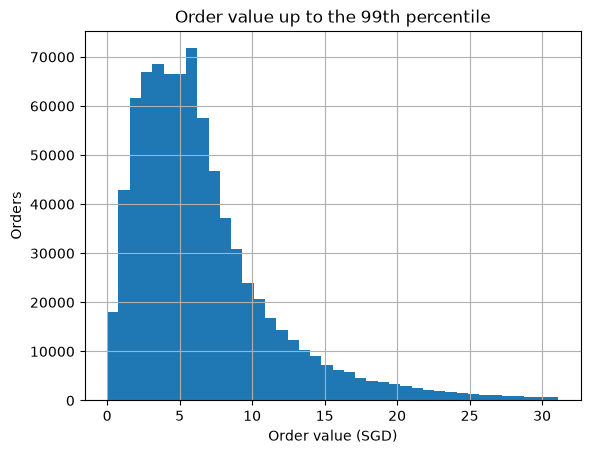

In [23]:
orders["order_value"].loc[orders["order_value"] <= orders["order_value"].quantile(0.99)].hist(bins=40)
plt.title("Order value up to the 99th percentile")
plt.xlabel("Order value (SGD)")
plt.ylabel("Orders")
plt.show()

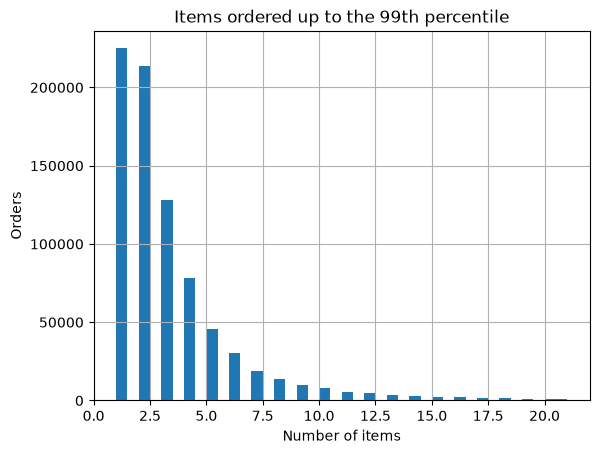

In [24]:
orders["num_items_ordered"].loc[orders["num_items_ordered"] <= orders["num_items_ordered"].quantile(0.99)].hist(bins=40)
plt.title("Items ordered up to the 99th percentile")
plt.xlabel("Number of items")
plt.ylabel("Orders")
plt.show()

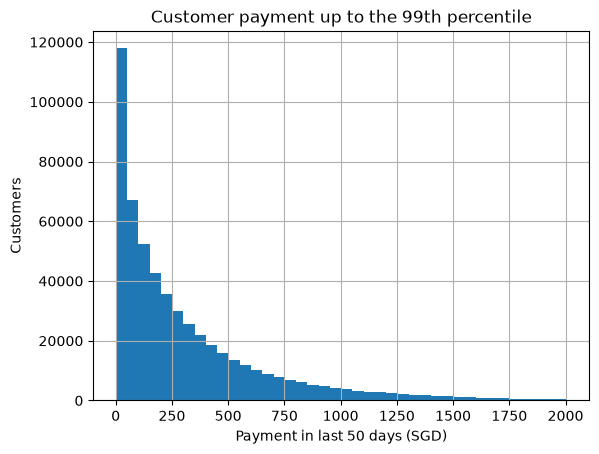

In [25]:
customers["total_payment_last_50days"].loc[customers["total_payment_last_50days"] <= customers["total_payment_last_50days"].quantile(0.99)].hist(bins=40)
plt.title("Customer payment up to the 99th percentile")
plt.xlabel("Payment in last 50 days (SGD)")
plt.ylabel("Customers")
plt.show()

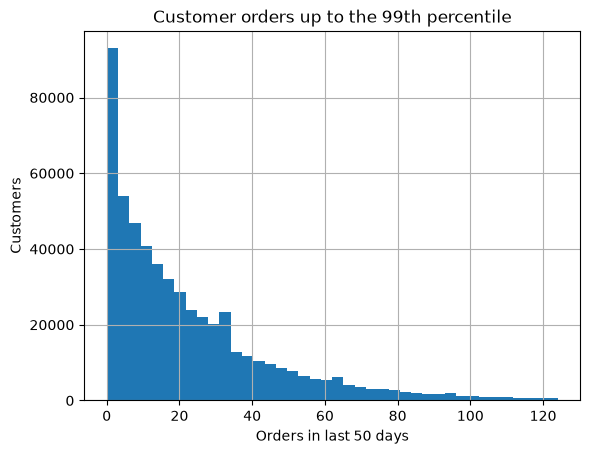

In [26]:
customers["num_orders_last_50days"].loc[customers["num_orders_last_50days"] <= customers["num_orders_last_50days"].quantile(0.99)].hist(bins=40)
plt.title("Customer orders up to the 99th percentile")
plt.xlabel("Orders in last 50 days")
plt.ylabel("Customers")
plt.show()

## Fraud distribution and patterns

The current fraud class distribution and charts use development-eligible labels only. The historical full-history EDA examined the complete label file before the holdout was defined; its original class analysis was not test-blind. These charts show associations, not causes. Refund and customer snapshot fields are excluded because availability at the prediction time is uncertain.


,count,percent
is_fraud,,
0,719164,89.253876
1,86587,10.746124


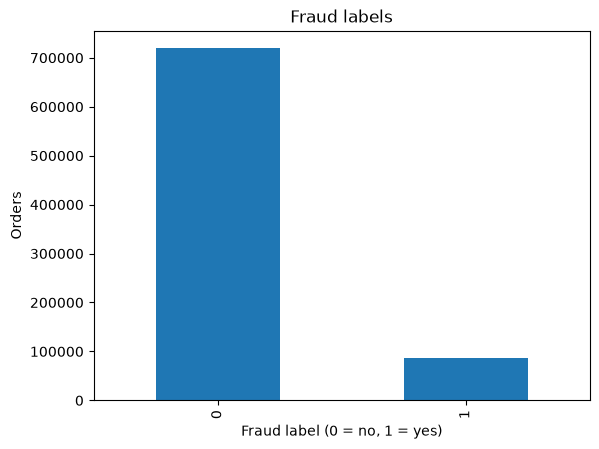

In [27]:
fraud_counts = labels["is_fraud"].value_counts(dropna=False).sort_index()
fraud_percent = labels["is_fraud"].value_counts(dropna=False, normalize=True).sort_index() * 100
display(pd.DataFrame({"count": fraud_counts, "percent": fraud_percent}))
fraud_counts.plot.bar()
plt.title("Fraud labels")
plt.xlabel("Fraud label (0 = no, 1 = yes)")
plt.ylabel("Orders")
plt.show()

Matched labeled orders: 805751


,orders,fraud_rate
collection,,
delivery,795893,0.10519
pickup,9858,0.29083


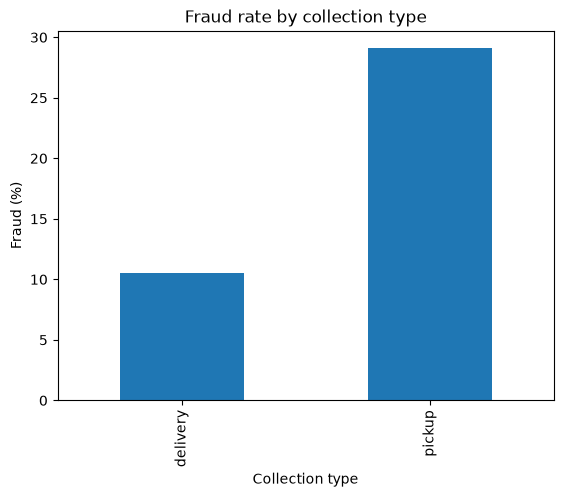

In [28]:
matched = joined[(joined["order_match"] == "both") & (joined["is_fraud"].isin([0, 1]))].copy()
print("Matched labeled orders:", len(matched))
matched["collection"] = matched["collect_type"].str.strip().str.lower().fillna("missing")
collection_rates = matched.groupby("collection")["is_fraud"].agg(["size", "mean"])
collection_rates.columns = ["orders", "fraud_rate"]
display(collection_rates)
(collection_rates["fraud_rate"] * 100).plot.bar()
plt.title("Fraud rate by collection type")
plt.xlabel("Collection type")
plt.ylabel("Fraud (%)")
plt.show()

,orders,fraud_rate
value_band,,
"(-0.001, 2.769]",161152,0.140191
"(2.769, 4.633]",161152,0.104758
"(4.633, 6.482]",161150,0.087254
"(6.482, 9.626]",161147,0.085704
"(9.626, 662.875]",161150,0.119398


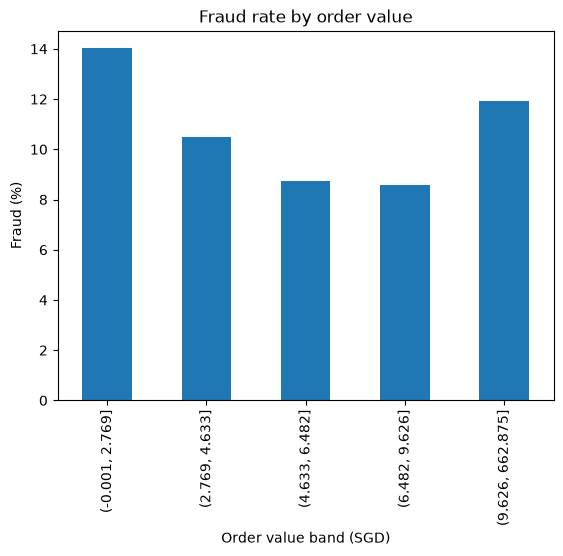

In [29]:
matched["value_band"] = pd.qcut(matched["order_value"], 5, duplicates="drop")
value_rates = matched.groupby("value_band", observed=True)["is_fraud"].agg(["size", "mean"])
value_rates.columns = ["orders", "fraud_rate"]
display(value_rates)
(value_rates["fraud_rate"] * 100).plot.bar()
plt.title("Fraud rate by order value")
plt.xlabel("Order value band (SGD)")
plt.ylabel("Fraud (%)")
plt.show()

## Data quality recommendations and limitations

- **PBI 02:** Standardize safe country and collection-type casing, confirm ambiguous Boolean values, review missingness and suspicious amounts, and quarantine invalid or conflicting keys rather than deleting records arbitrarily.
- **PBI 03:** Keep the label, identifiers, refund data and customer snapshots out of model features until their availability at the prediction time is established. Fit transformations on training data only.
- **Isolation:** The earlier full-history EDA examined labels before the holdout existed. Current analyses use only training and validation records; no new test outcomes are produced.


The current PBI 01 calculations above use development-eligible data only. The next sections clean those same in-memory tables and prepare the historical training and validation split. The original full-history EDA is acknowledged as historical evidence and is not rerun.


In [30]:
import gc
import seaborn as sns
from IPython.display import display, Image

from src.data_cleaning import clean_customers, clean_orders, clean_labels, check_relationships
from src.feature_engineering import prepare_training_data, fit_preprocessor, INPUT_FEATURES
from src.train_hq import load_finalized_results

del customers_clean, orders_clean, labels_clean
del order_links, customer_links, order_countries, customer_countries
del unique_labels, unique_orders, joined, matched
del customer_numbers, order_numbers, customer_outliers, order_outliers
gc.collect()
print("Historical EDA complete; starting reusable cleaning.")

Historical EDA complete; starting reusable cleaning.


## PBI 02 — Development-data cleaning

The sealed-data reader passes only development-eligible rows to these cleaners. Inputs are not modified. Cleaners return retained rows, rejected original rows and reports; invalid optional features are counted and retained as missing where appropriate.

For incoming files, `read_dataset_csv(path)` infers `customers`, `orders` or `labels` from the filename prefix, preserves key columns as text, and validates the schema before cleaning. Run All continues to use the sealed-data loader, so this section does not open incoming files or sealed test records.


In [31]:
print("Cleaning customers...")
customers_clean, customers_rejected, customer_report = clean_customers(customers)
print("Cleaning orders...")
orders_clean, orders_rejected, order_report = clean_orders(orders)
print("Cleaning labels...")
labels_clean, labels_rejected, label_report = clean_labels(labels)
print("Cleaning complete.")

Cleaning customers...


Cleaning orders...


Cleaning labels...


Cleaning complete.


In [32]:
cleaning_reports = pd.DataFrame([customer_report, order_report, label_report],
                                index=["customers", "orders", "labels"])
display(cleaning_reports[["received", "changed", "rejected", "retained",
                          "exact_duplicate_rows", "conflicting_key_rows", "invalid_key_rows"]])
print("Customer quality checks:")
display(pd.Series(customer_report["issues"], name="count"))
print("Order quality checks:")
display(pd.Series(order_report["issues"], name="count"))
print("Label quality checks:")
display(pd.Series(label_report["issues"], name="count"))
print("Observed order categories (new categories are retained):")
display(order_report["category_values"])

print("Missing values after cleaning:")
display(pd.DataFrame({"customers": customer_report["missing_values"],
                      "orders": order_report["missing_values"],
                      "labels": label_report["missing_values"]}).fillna(0).astype(int))
print("Rows flagged for review (sample):")
display(pd.DataFrame(order_report["flagged_records"]).head())

,received,changed,rejected,retained,exact_duplicate_rows,conflicting_key_rows,invalid_key_rows
customers,544534,333,0,544534,0,0,0
orders,805763,805763,0,805763,0,0,0
labels,805751,260,0,805751,0,0,0


Customer quality checks:


mobile_verified_unrecognized                100
num_orders_last_50days_invalid                0
num_cancelled_orders_last_50days_invalid      0
num_refund_orders_last_50days_invalid         0
num_associated_customers_invalid              0
total_payment_last_50days_invalid             0
first_order_datetime_invalid                  0
cancellations_exceed_orders                   0
refunds_exceed_orders                         0
Name: count, dtype: int64

Order quality checks:


order_value_invalid                0
num_items_ordered_invalid          0
refund_value_invalid               0
order_date_invalid                 0
refund_exceeds_order_value    166148
Name: count, dtype: int64

Label quality checks:


... (3 outputs left out)

Missing values after cleaning:


,customers,orders,labels
country_code,0,0,0
customer_id,0,0,0
mobile_verified,100,0,0
num_orders_last_50days,0,0,0
num_cancelled_orders_last_50days,0,0,0
num_refund_orders_last_50days,0,0,0
total_payment_last_50days,0,0,0
num_associated_customers,0,0,0
first_order_datetime,405,0,0
order_id,0,0,0


Rows flagged for review (sample):


,source_row,issues,country_code,order_id
0,16,[refund_exceeds_order_value],PH,f923e66f66
1,18,[refund_exceeds_order_value],PH,f36df68674
2,38,[refund_exceeds_order_value],PH,51dea40200
3,40,[refund_exceeds_order_value],PH,1f5746035b
4,48,[refund_exceeds_order_value],PH,a047c20fd2


In [33]:
relationships = check_relationships(customers_clean, orders_clean, labels_clean)
print("Labels and orders:")
display(pd.Series(relationships["order_counts"], name="rows"))
print("Labels and customers:")
display(pd.Series(relationships["customer_counts"], name="rows"))

Labels and orders:


both          805751
right_only        12
left_only          0
Name: rows, dtype: int64

Labels and customers:


both          805750
left_only          1
right_only         0
Name: rows, dtype: int64

## PBI 03 — Chronological split and shared eight-feature preprocessing

The shared schema is `order_value`, `num_items_ordered`, `order_weekday`, `order_month`, `country_code`, `collect_type`, `payment_method`, and `days_since_first_order`. Customer history is joined through the validated country/customer key. Missing or future first-order dates become missing. The fixed training/validation boundary is unchanged; sealed-period records are excluded before feature joins. One preprocessor is fitted on training rows and reused for validation.

The first-order field is only point-in-time safe if its source is an as-of first order timestamp. The current files call it the first recorded order but do not prove serving-time availability; this remains a documented PBI 10 data-source check.

In [34]:
from src.data_access import VALIDATION_START

print("Preparing the training and validation split...")
x_train, y_train, x_val, y_val, x_test, y_test, split, train_dates = prepare_training_data(
    customers_clean, orders_clean, labels_clean,
    include_test=False,
    include_training_dates=True,
    validation_start_date=VALIDATION_START,
)
assert x_test is None and y_test is None
split.pop("training_dates")  # dates are metadata, never model features
split_table = pd.DataFrame({
    "rows": [split["training_rows"], split["validation_rows"]],
    "first_date": [split["train_first_date"], split["validation_first_date"]],
    "last_date": [split["train_last_date"], split["validation_last_date"]],
}, index=["training", "validation"])
display(split_table)
print("Input features:", INPUT_FEATURES)


Preparing the training and validation split...


,rows,first_date,last_date
training,660773,2022-11-12,2023-03-14
validation,144978,2023-03-15,2023-04-13


Input features: ['order_value', 'num_items_ordered', 'order_weekday', 'order_month', 'country_code', 'collect_type', 'payment_method', 'days_since_first_order']


In [35]:
print("Fitting preprocessing on training data only...")
preprocessor = fit_preprocessor(x_train)
print("Training rows:", len(x_train))
print("Validation rows:", len(x_val))
print("Transformed features:", len(preprocessor.get_feature_names_out()))
print("The benchmark will transform training and validation once using this fitted preprocessor.")

Fitting preprocessing on training data only...


Training rows: 660773
Validation rows: 144978
Transformed features: 30
The benchmark will transform training and validation once using this fitted preprocessor.


# PBI 06 — Fraud model development

The seven model families use the same eight PBI 03 features and the frozen chronological split. The newest approximately 20% of whole training dates are reserved for threshold calibration. Two expanding folds inside the earlier training period compare configurations at threshold 0.5. Each fold fits its own shared preprocessor. All reported model versions fit on the same earlier training rows. Validation supplies evaluation metrics only.

The customer first-order timestamp and independently available order-to-customer mapping still require point-in-time verification. The sealed period is excluded by the PBI 01–03 development path.

In [36]:
import os

from src.train_hq import evaluation_dates, research_stages, threshold_curve

mode = os.environ.get("PBI06_MODE", "reuse")
validation_dates = evaluation_dates(orders_clean, labels_clean, x_val)
stages = research_stages(
    x_train, y_train, train_dates, x_val, y_val, validation_dates, split,
    mode=mode, run_id=os.environ.get("PBI06_RUN_ID"),
)
metric_columns = [
    "family", "f1", "precision", "recall", "average_precision", "roc_auc",
    "accuracy", "false_positive_rate", "tn", "fp", "fn", "tp",
    "training_seconds", "prediction_seconds", "mean_f1", "std_f1", "config", "run_id",
]
print("PBI 06 mode:", mode)

PBI 06 mode: reuse


## 1. Baselines and diagnosis

All seven baselines use reproducible fixed configurations, one sample weight per training observation, and a 0.5 threshold. Compare recall with precision and false alarms before interpreting F1. A low recall means missed fraud. A low precision means more legitimate orders enter the review queue.

,family,f1,precision,recall,average_precision,roc_auc,accuracy,false_positive_rate,tn,fp,fn,tp,training_seconds,prediction_seconds,mean_f1,std_f1,config,run_id
family,,,,,,,,,,,,,,,,,,
xgboost,xgboost,0.543524,0.418809,0.774012,0.523596,0.847153,0.822980,0.169302,104035,21203,4461,15279,0.574243,0.017007,0.408996,0.014202,"{'params': {}, 'weight': 1.0}",68247f279d9e4ec4b9b6f6c882f255f6
lightgbm,lightgbm,0.540652,0.415569,0.773455,0.522166,0.847642,0.821049,0.171450,103766,21472,4472,15268,0.557900,0.080486,0.407935,0.015431,"{'params': {}, 'weight': 1.0}",6a6564a5d525432f8a39ec5dc6f72f0a
random_forest,random_forest,0.540459,0.413126,0.781256,0.526523,0.847699,0.819104,0.174931,103330,21908,4318,15422,2.296275,0.038531,0.400879,0.015267,"{'params': {}, 'weight': 1.0}",11ad74bc96334e31b93f6b4527e3c544
hist_gradient_boosting,hist_gradient_boosting,0.539990,0.414875,0.773151,0.518977,0.847360,0.820642,0.171873,103713,21525,4478,15262,1.651477,0.069512,0.406723,0.016489,"{'params': {}, 'weight': 1.0}",3a4da8756d6f4a6f9fb542949da3b9c7
catboost,catboost,0.538475,0.410798,0.781307,0.524681,0.849816,0.817641,0.176632,103117,22121,4317,15423,1.438070,0.005274,0.398807,0.015854,"{'params': {}, 'weight': 1.0}",1003dca400344927aca47c9e89f61bd2
gradient_boosting,gradient_boosting,0.532694,0.403904,0.782067,0.518083,0.847198,0.813172,0.181926,102454,22784,4302,15438,32.997962,0.061774,0.397851,0.014125,"{'params': {}, 'weight': 1.0}",840ba683b76844bea8808dddbc714608
logistic_regression,logistic_regression,0.477997,0.341103,0.798430,0.508129,0.841734,0.762557,0.243097,94793,30445,3979,15761,1.445832,0.001108,0.354272,0.013754,"{'params': {}, 'weight': 1.0}",41c73e06a7c44321af16bd66ad2ac612


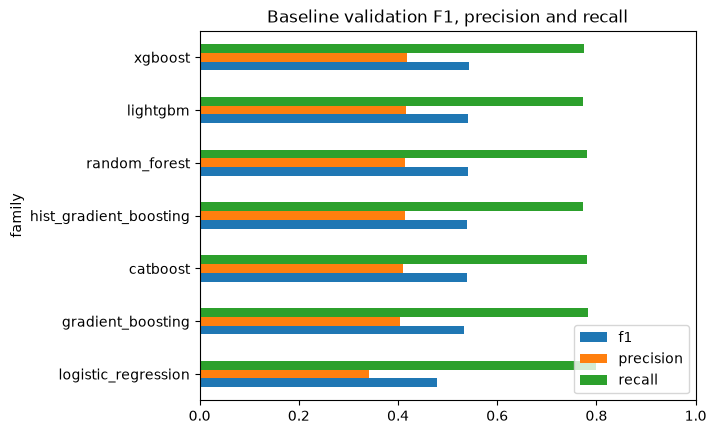

In [37]:
baseline = pd.DataFrame(next(stages)).set_index("family", drop=False)
display(baseline[metric_columns].sort_values("f1", ascending=False))
baseline.sort_values("f1")[["f1", "precision", "recall"]].plot.barh(
    title="Baseline validation F1, precision and recall", xlim=(0, 1))
plt.show()

## 2. Ordinary hyperparameter tuning

Each family compares ten configurations including its baseline. Mean training fold fraud F1 ranks configurations. Average precision and smaller model size break ties. Each trial also varies the strength of balanced training sample weights. Outer validation describes the result of the already selected configuration.

In [38]:
ordinary = pd.DataFrame(next(stages)).set_index("family", drop=False)
display(ordinary[metric_columns].assign(change_vs_baseline=ordinary.f1 - baseline.f1)
        .sort_values("f1", ascending=False))

,family,f1,precision,recall,average_precision,roc_auc,accuracy,false_positive_rate,tn,fp,fn,tp,training_seconds,prediction_seconds,mean_f1,std_f1,config,run_id,change_vs_baseline
family,,,,,,,,,,,,,,,,,,,
catboost,catboost,0.546434,0.484305,0.626849,0.524951,0.850076,0.858310,0.105208,112062,13176,7366,12374,3.006833,0.007761,0.448758,0.012091,"{'params': {'iterations': 155, 'depth': 7, 'le...",8c3b22e3730746a891f589c26940091c,0.007959
lightgbm,lightgbm,0.545418,0.486628,0.620365,0.521865,0.847562,0.859199,0.103156,112319,12919,7494,12246,0.803293,0.130568,0.448232,0.014751,"{'params': {'n_estimators': 120, 'num_leaves':...",2a1056b2c0bc4759b5c8213d7a0bd443,0.004767
xgboost,xgboost,0.544585,0.487054,0.617528,0.524144,0.846734,0.859372,0.102509,112400,12838,7550,12190,0.843347,0.031582,0.449504,0.013006,"{'params': {'n_estimators': 100, 'max_depth': ...",dd07c62c0e0e43a18d42fc379cb2d85e,0.001062
random_forest,random_forest,0.543441,0.480517,0.625329,0.506899,0.849854,0.856937,0.106557,111893,13345,7396,12344,2.956274,0.038458,0.448739,0.012149,"{'params': {'n_estimators': 25, 'max_depth': 1...",d483cbecfa624b8f9cd31c6bf5fa1625,0.002982
hist_gradient_boosting,hist_gradient_boosting,0.537184,0.490861,0.593161,0.515904,0.848068,0.860834,0.096975,113093,12145,8031,11709,1.890102,0.082498,0.449409,0.015719,"{'params': {'max_iter': 70, 'max_leaf_nodes': ...",459a36a85b36415d8dd81c2fe5f898e7,-0.002806
gradient_boosting,gradient_boosting,0.525190,0.511199,0.539970,0.516911,0.849099,0.867063,0.081381,115046,10192,9081,10659,16.618223,0.038415,0.441277,0.013976,"{'params': {'n_estimators': 45, 'max_depth': 3...",c90bd18e4e4447b8b6a4fd51f3f80664,-0.007504
logistic_regression,logistic_regression,0.517770,0.481066,0.560537,0.507008,0.840845,0.857834,0.095307,113302,11936,8675,11065,1.713572,0.001077,0.405487,0.020625,"{'params': {'C': 20, 'max_iter': 200}, 'weight...",95ba837d12ad4f868762a44500e65c88,0.039773


## 3. Advanced hyperparameter tuning

Each family compares 24 configurations including its ordinary winner. The wider parameter spaces cover applicable regularization, sampling and complexity interactions. The folds, scoring rule and threshold remain the same. Trial and fold details are available in MLflow.

In [39]:
advanced = pd.DataFrame(next(stages)).set_index("family", drop=False)
display(advanced[metric_columns].assign(change_vs_ordinary=advanced.f1 - ordinary.f1)
        .sort_values("f1", ascending=False))

,family,f1,precision,recall,average_precision,roc_auc,accuracy,false_positive_rate,tn,fp,fn,tp,training_seconds,prediction_seconds,mean_f1,std_f1,config,run_id,change_vs_ordinary
family,,,,,,,,,,,,,,,,,,,
catboost,catboost,0.546434,0.484305,0.626849,0.524951,0.850076,0.858310,0.105208,112062,13176,7366,12374,3.006833,0.007761,0.448758,0.012091,"{'params': {'iterations': 155, 'depth': 7, 'le...",33e0bce9dccf44ad8bfe44aa50c958b6,0.000000
random_forest,random_forest,0.546150,0.486518,0.622442,0.523255,0.851193,0.859144,0.103547,112270,12968,7453,12287,8.457462,0.113309,0.450711,0.011909,"{'params': {'n_estimators': 55, 'max_depth': 1...",231ad02c1df54fe38c2463efe8416cba,0.002708
lightgbm,lightgbm,0.545418,0.486628,0.620365,0.521865,0.847562,0.859199,0.103156,112319,12919,7494,12246,0.803293,0.130568,0.448232,0.014751,"{'params': {'n_estimators': 120, 'num_leaves':...",3831ea7f26f642c0aa31434d956e8663,0.000000
xgboost,xgboost,0.543889,0.490065,0.610993,0.523368,0.848380,0.860468,0.100209,112688,12550,7679,12061,0.786290,0.027484,0.450620,0.012722,"{'params': {'n_estimators': 110, 'max_depth': ...",01a3a6d07d3246d09f809867cab8fe8c,-0.000697
gradient_boosting,gradient_boosting,0.537374,0.483046,0.605471,0.523780,0.847646,0.858054,0.102134,112447,12791,7788,11952,17.316130,0.082492,0.443597,0.016140,"{'params': {'n_estimators': 110, 'learning_rat...",a4598a508f7e4040962f97548e5d7c0b,0.012184
hist_gradient_boosting,hist_gradient_boosting,0.537184,0.490861,0.593161,0.515904,0.848068,0.860834,0.096975,113093,12145,8031,11709,1.890102,0.082498,0.449409,0.015719,"{'params': {'max_iter': 70, 'max_leaf_nodes': ...",dd0d4c6d1e7b41f3b695396819def5af,0.000000
logistic_regression,logistic_regression,0.517770,0.481066,0.560537,0.507008,0.840845,0.857834,0.095307,113302,11936,8675,11065,1.713572,0.001077,0.405487,0.020625,"{'params': {'C': 20, 'max_iter': 200}, 'weight...",63db305ddd604befac13c12759a1a010,0.000000


## 4. Best configuration for each family

Configuration selection uses the same training fold scores across all three stages. The stage with the highest observed outer validation F1 is shown for context.

In [40]:
selected = pd.DataFrame(next(stages)).set_index("family")
display(selected[["stage", "config", "mean_f1", "std_f1", "mean_ap",
                  "highest_observed_validation_stage"]])

,stage,config,mean_f1,std_f1,mean_ap,highest_observed_validation_stage
family,,,,,,
logistic_regression,ordinary,"{'params': {'C': 20, 'max_iter': 200}, 'weight...",0.405487,0.020625,0.374099,ordinary
random_forest,advanced,"{'params': {'n_estimators': 55, 'max_depth': 1...",0.450711,0.011909,0.431987,advanced
xgboost,advanced,"{'params': {'n_estimators': 110, 'max_depth': ...",0.450620,0.012722,0.440680,ordinary
lightgbm,ordinary,"{'params': {'n_estimators': 120, 'num_leaves':...",0.448232,0.014751,0.442298,ordinary
catboost,ordinary,"{'params': {'iterations': 155, 'depth': 7, 'le...",0.448758,0.012091,0.440850,ordinary
hist_gradient_boosting,ordinary,"{'params': {'max_iter': 70, 'max_leaf_nodes': ...",0.449409,0.015719,0.430314,baseline
gradient_boosting,advanced,"{'params': {'n_estimators': 110, 'learning_rat...",0.443597,0.016140,0.425411,advanced


## 5. Threshold calibration

Each selected model scores the reserved training calibration dates. The full precision–recall threshold sequence supplies the cutoff that maximizes fraud F1. The same fitted model provides the outer validation probabilities used at both thresholds.

Development periods


,first,last,rows
fit,2022-11-12,2023-02-17,525226
calibration,2023-02-18,2023-03-14,135547
validation,2023-03-15,2023-04-13,144978


,threshold,calibration_fixed_f1,calibration,calibration_drift,fp,fn,validation F1 at 0.5,validation optimized F1,FP at 0.5,FN at 0.5
family,,,,,,,,,,
random_forest,0.510997,0.447635,"{'f1': 0.4492868260570029, 'precision': 0.3578...","[{'period': {'first': '2023-02-18', 'last': '2...",12410,7743,0.546150,0.543502,12968,7453
xgboost,0.547957,0.446089,"{'f1': 0.4497836746466686, 'precision': 0.3882...","[{'period': {'first': '2023-02-18', 'last': '2...",9689,9183,0.543889,0.528035,12550,7679
gradient_boosting,0.528222,0.441153,"{'f1': 0.44686059088062846, 'precision': 0.382...","[{'period': {'first': '2023-02-18', 'last': '2...",10189,9054,0.537374,0.526210,12791,7788
lightgbm,0.580598,0.446799,"{'f1': 0.45047658516369665, 'precision': 0.396...","[{'period': {'first': '2023-02-18', 'last': '2...",9089,9554,0.545418,0.522158,12919,7494
catboost,0.576291,0.446149,"{'f1': 0.4486481609575652, 'precision': 0.3996...","[{'period': {'first': '2023-02-18', 'last': '2...",8804,9690,0.546434,0.520806,13176,7366
logistic_regression,0.489344,0.426202,"{'f1': 0.42737195633921077, 'precision': 0.346...","[{'period': {'first': '2023-02-18', 'last': '2...",12762,8317,0.517770,0.520114,11936,8675
hist_gradient_boosting,0.545706,0.443122,"{'f1': 0.44624613922546924, 'precision': 0.393...","[{'period': {'first': '2023-02-18', 'last': '2...",9033,9693,0.537184,0.517620,12145,8031


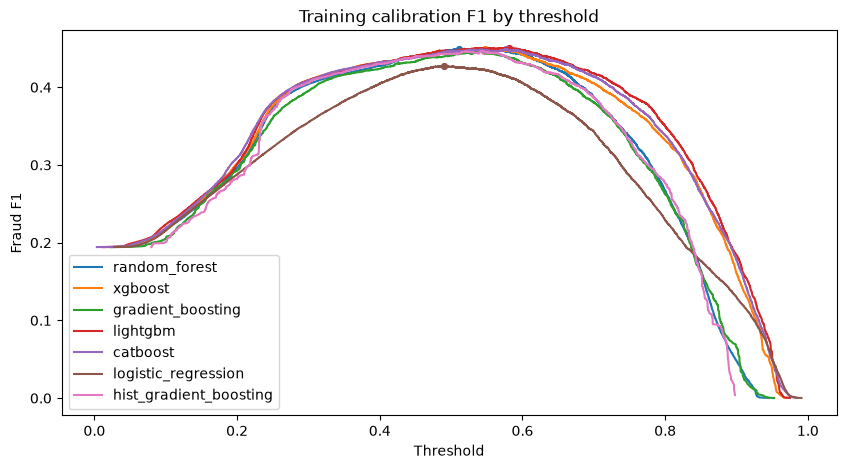

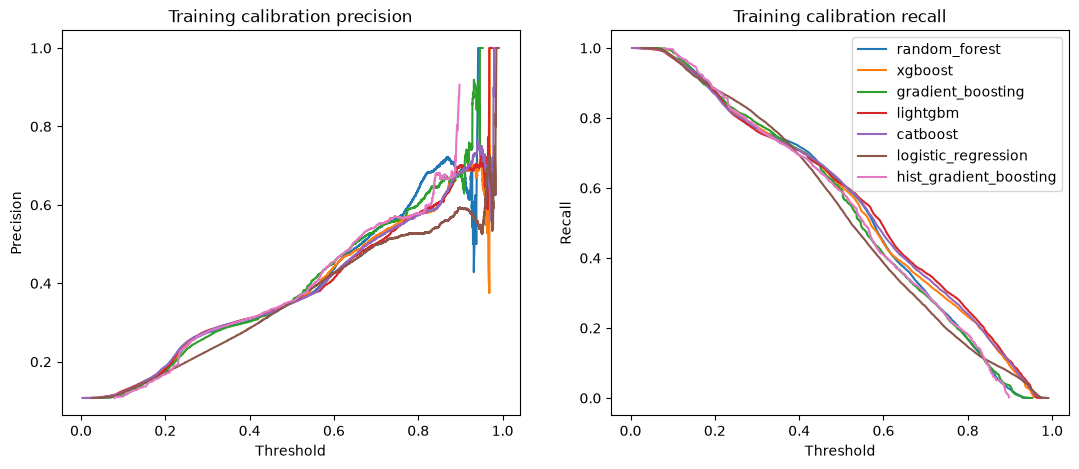

In [41]:
evidence, probabilities = next(stages)
final = pd.DataFrame(evidence["final"]).set_index("family")
print("Development periods")
display(pd.DataFrame(evidence["periods"]).T)
thresholds = final[["threshold", "calibration_fixed_f1", "calibration",
                    "calibration_drift", "fp", "fn"]].copy()
thresholds["validation F1 at 0.5"] = final.fixed.map(lambda m: m["f1"])
thresholds["validation optimized F1"] = final.f1
thresholds["FP at 0.5"] = final.fixed.map(lambda m: m["fp"])
thresholds["FN at 0.5"] = final.fixed.map(lambda m: m["fn"])
display(thresholds)

fig, ax = plt.subplots(figsize=(10, 5))
for name, row in final.iterrows():
    curve = threshold_curve(probabilities["calibration_truth"], probabilities[f"calibration_{name}"])
    ax.plot(curve.threshold, curve.f1, label=name)
    ax.scatter(row.threshold, row.calibration["f1"], s=18)
ax.set(xlabel="Threshold", ylabel="Fraud F1", title="Training calibration F1 by threshold")
ax.legend()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in final.index:
    curve = threshold_curve(probabilities["calibration_truth"], probabilities[f"calibration_{name}"])
    axes[0].plot(curve.threshold, curve.precision, label=name)
    axes[1].plot(curve.threshold, curve.recall, label=name)
for ax, metric in zip(axes, ["Precision", "Recall"]):
    ax.set(xlabel="Threshold", ylabel=metric, title=f"Training calibration {metric.lower()}")
axes[1].legend()
plt.show()

## 6. Final validation comparison

The leaderboard ranks optimized versions by validation fraud F1, then average precision. The 0.5 results and the training-selected thresholds show how each cutoff moves the balance between missed fraud and review workload.

,baseline_f1,ordinary_f1,advanced_f1,selection_source,config,selected_f1_at_0.5,threshold,f1,precision,recall,...,roc_auc,accuracy,false_positive_rate,tn,fp,fn,tp,training_seconds,prediction_seconds,run_id
family,,,,,,,,,,,,,,,,,,,,,
random_forest,0.540459,0.543441,0.546150,advanced,"{'params': {'n_estimators': 55, 'max_depth': 1...",0.546150,0.510997,0.543502,0.491539,0.607751,...,0.851193,0.860993,0.099091,112828,12410,7743,11997,8.457462,0.113309,adc11d5eedb54dc9a3086cad7e6c4270
xgboost,0.543524,0.544585,0.543889,advanced,"{'params': {'n_estimators': 110, 'max_depth': ...",0.543889,0.547957,0.528035,0.521436,0.534802,...,0.848380,0.869829,0.077365,115549,9689,9183,10557,0.786290,0.027484,289945f86f2449ea8fe7ff2421249eaa
gradient_boosting,0.532694,0.525190,0.537374,advanced,"{'params': {'n_estimators': 110, 'learning_rat...",0.537374,0.528222,0.526210,0.511904,0.541337,...,0.847646,0.867270,0.081357,115049,10189,9054,10686,17.316130,0.082492,5e4b1bd4257f4e98920647519f59550c
lightgbm,0.540652,0.545418,0.545418,ordinary,"{'params': {'n_estimators': 120, 'num_leaves':...",0.545418,0.580598,0.522158,0.528457,0.516008,...,0.847562,0.871408,0.072574,116149,9089,9554,10186,0.803293,0.130568,8fd15510396444e29e0308f423fe97df
catboost,0.538475,0.546434,0.546434,ordinary,"{'params': {'iterations': 155, 'depth': 7, 'le...",0.546434,0.576291,0.520806,0.533043,0.509119,...,0.850076,0.872436,0.070298,116434,8804,9690,10050,3.006833,0.007761,652ffc4da1894319aa859515e14c2fce
logistic_regression,0.477997,0.517770,0.517770,ordinary,"{'params': {'C': 20, 'max_iter': 200}, 'weight...",0.517770,0.489344,0.520114,0.472318,0.578673,...,0.840845,0.854606,0.101902,112476,12762,8317,11423,1.713572,0.001077,2a91d0ecab36428989a0efecc96c80e6
hist_gradient_boosting,0.539990,0.537184,0.537184,ordinary,"{'params': {'max_iter': 70, 'max_leaf_nodes': ...",0.537184,0.545706,0.517620,0.526572,0.508967,...,0.848068,0.870836,0.072127,116205,9033,9693,10047,1.890102,0.082498,bec883e5805e4614aaabe32dc0db1f15


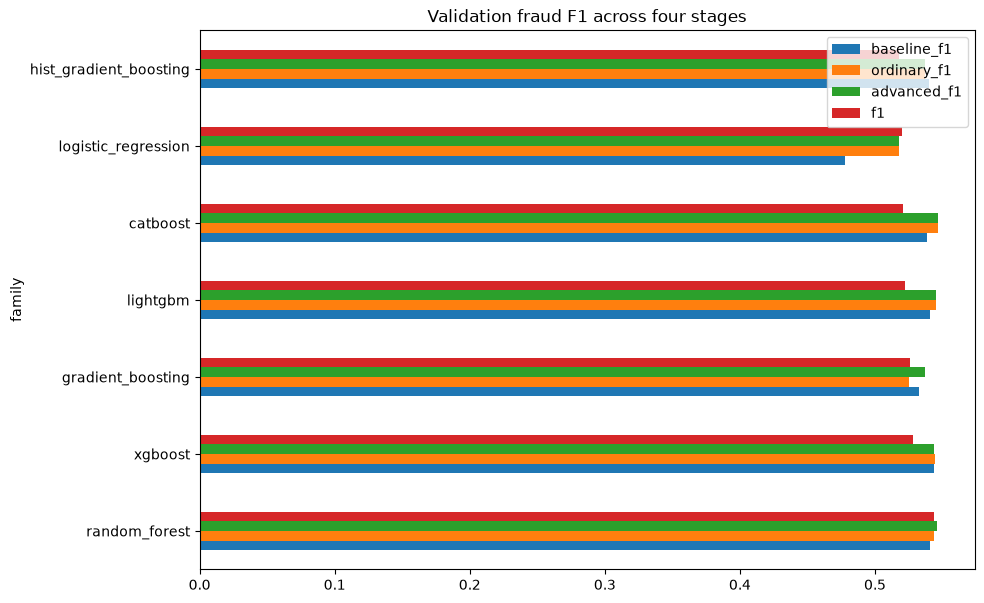

In [42]:
leaderboard = final[["selection_source", "config", "threshold", "f1", "precision", "recall",
                     "average_precision", "roc_auc", "accuracy", "false_positive_rate",
                     "tn", "fp", "fn", "tp", "training_seconds", "prediction_seconds", "run_id"]].copy()
leaderboard.insert(0, "baseline_f1", baseline.f1)
leaderboard.insert(1, "ordinary_f1", ordinary.f1)
leaderboard.insert(2, "advanced_f1", advanced.f1)
leaderboard.insert(5, "selected_f1_at_0.5", final.fixed.map(lambda m: m["f1"]))
display(leaderboard)

columns = ["baseline_f1", "ordinary_f1", "advanced_f1", "f1"]
leaderboard[columns].plot.barh(figsize=(10, 7), title="Validation fraud F1 across four stages")
plt.show()

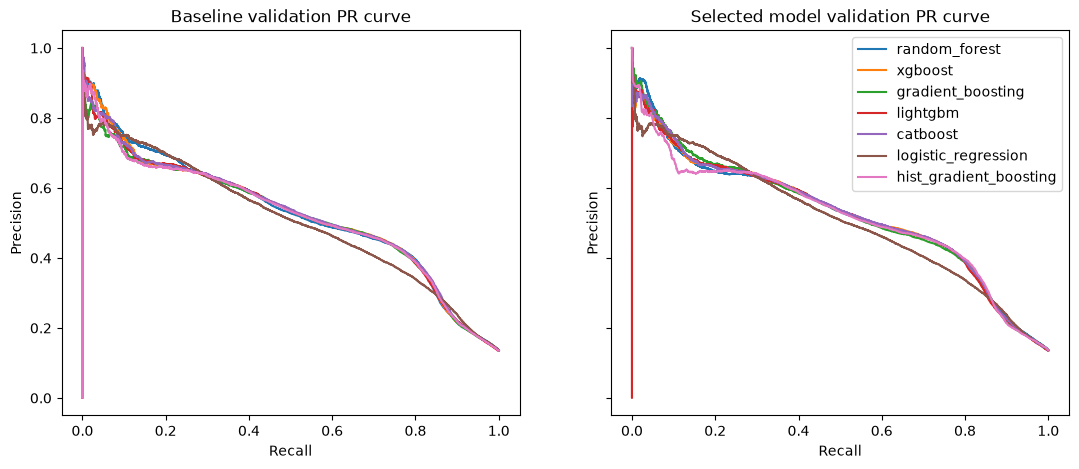

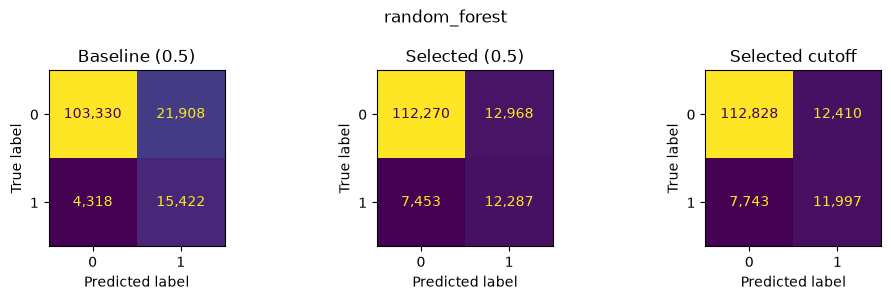

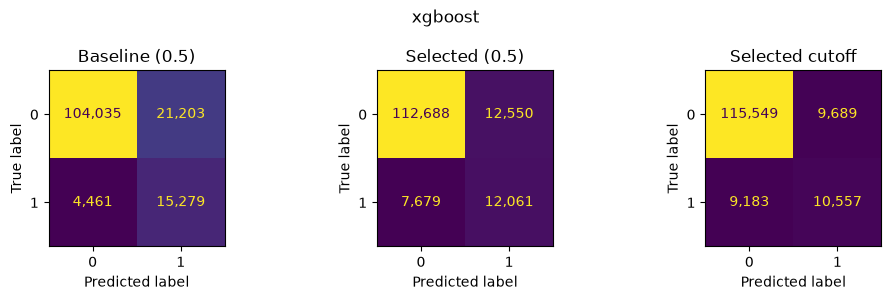

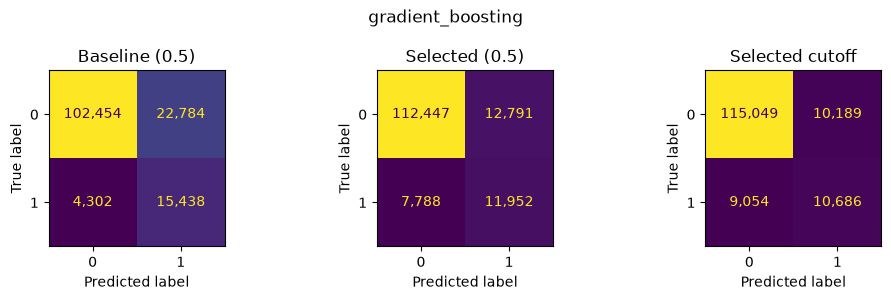

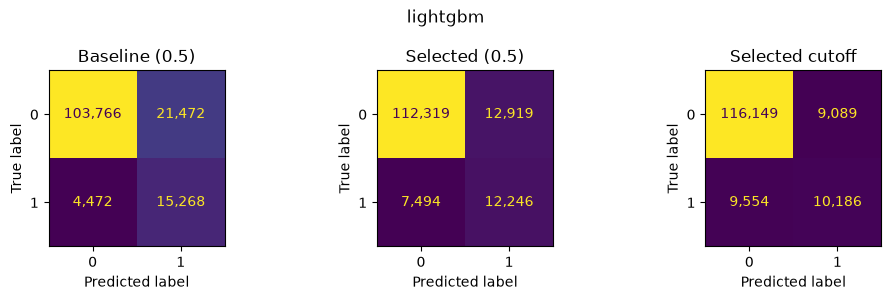

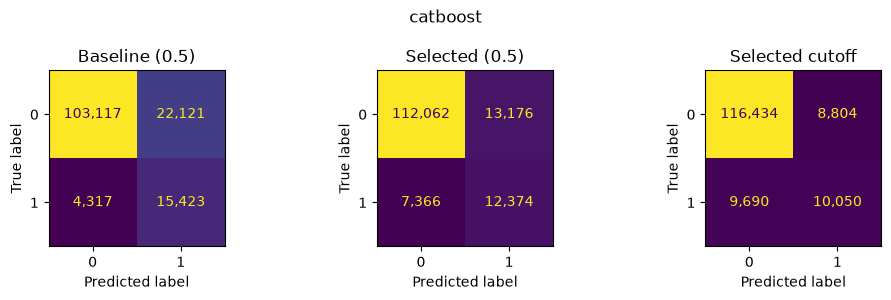

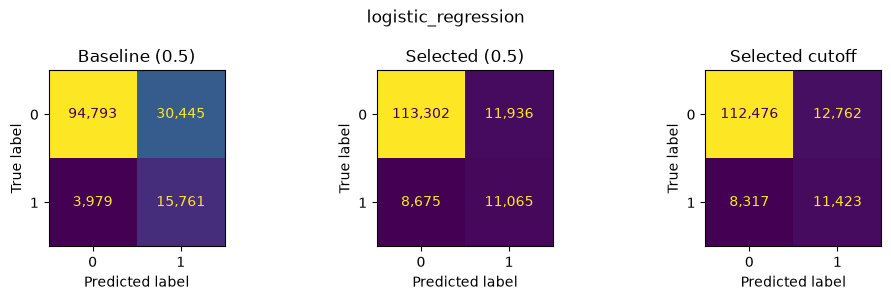

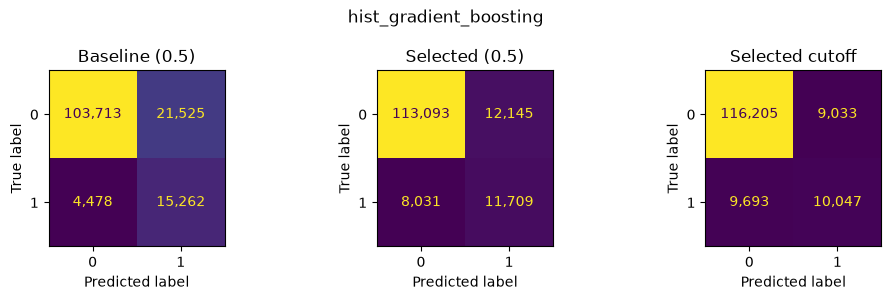

In [43]:
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for name in final.index:
    for stage, ax in zip(["baseline", "final"], axes):
        p, r, _ = precision_recall_curve(y_val, probabilities[f"{stage}_{name}"])
        ax.plot(r, p, label=name)
for ax, title in zip(axes, ["Baseline", "Selected model"]):
    ax.set(xlabel="Recall", ylabel="Precision", title=f"{title} validation PR curve")
axes[1].legend()
plt.show()

for name, row in final.iterrows():
    fig, axes = plt.subplots(1, 3, figsize=(10, 3))
    for ax, metrics, title in zip(axes, [baseline.loc[name], row.fixed, row],
                                  ["Baseline (0.5)", "Selected (0.5)", "Selected cutoff"]):
        matrix = [[metrics["tn"], metrics["fp"]], [metrics["fn"], metrics["tp"]]]
        ConfusionMatrixDisplay(np.asarray(matrix)).plot(ax=ax, colorbar=False, values_format=",.0f")
        ax.set_title(title)
    fig.suptitle(name)
    fig.tight_layout()
    plt.show()

In [44]:
trial_rows = pd.DataFrame(evidence["trials"])
display(trial_rows.groupby(["requested_stage", "family"]).agg(
    configurations=("config", "size"), reused=("reused", "sum"),
    failures=("status", lambda s: s.eq("failed").sum())))
display(pd.Series(evidence["seconds"], name="wall seconds"))
print("Local MLflow research parent run:", evidence["run_id"])
print("Evidence fingerprint:", evidence["fingerprint"])

configurations  reused  failures
requested_stage family                                                  
advanced        catboost                            24       1         0
                gradient_boosting                   24       1         0
                hist_gradient_boosting              24       1         0
                lightgbm                            24       1         0
                logistic_regression                 24       1         0
                random_forest                       24       1         0
                xgboost                             24       1         0
baseline        catboost                             1       0         0
                gradient_boosting                    1       0         0
                hist_gradient_boosting               1       0         0
                lightgbm                             1       0         0
                logistic_regression                  1       0         0
                random_forest                        1       0         0
                xgboost                              1       0         0
ordinary        catboost                            10       1         0
                gradient_boosting                   10       1         0
                hist_gradient_boosting              10       1         0
                lightgbm                            10       1         0
                logistic_regression                 10       1         0
                random_forest                       10       1         0
                xgboost                             10       1         0

setup                       1.296100
baseline                   94.763586
ordinary                  505.412317
advanced                 1399.579794
threshold_and_logging       2.214214
artifact_verification       1.218438
Name: wall seconds, dtype: float64

Local MLflow research parent run: 939506bd3eb6434c8489d5871ea9778e
Evidence fingerprint: c52849e7a9a22643c6a2ce9a0305ee8aa34f8363ff0a4029e1e8cd39b6cbd1e3


## 7. Interpretation and reuse

False positives are legitimate orders sent to review. False negatives are missed fraud. Use the leaderboard and confusion counts together when discussing analyst capacity. A training-selected cutoff can score lower than 0.5 on later dates. The team makes the PBI 09 selection.

Set `PBI06_MODE=full` before launching the notebook kernel to execute research. The default `reuse` mode checks the dataset, features, split, dependencies and source fingerprints and verifies saved final artifacts. The PBI 10 callable `train_selected_models()` runs fixed configurations independently of the notebook. See the implementation report for exact commands, measured results and remaining integration requirements.

In local run `939506bd3eb6434c8489d5871ea9778e`, **random forest** led the calibrated validation ranking with F1 **0.5435**. It flagged 24,407 orders, including 12,410 legitimate orders, and missed 7,743 fraud orders. Compared with the same model at 0.5, training calibration reduced validation F1 for random forest, xgboost, gradient boosting, lightgbm, catboost, hist gradient boosting. See the reports for the full comparisons and operating trade-offs.